# Formal Specifications for Enzymatic Output Flux
### Ayush Pandey

We consider an enzymatic CRN subsystem
$$E+S\mathrel{\mathop{\rightleftharpoons}^{k_f}_{k_r}}C
\mathrel{\mathop{\longrightarrow}^{k_{\mathrm{cat}}}}E+P,$$
where $E,S,C,P$ denote the enzyme, substrate, complex, and product concentrations, and $k_f,k_r,k_{\mathrm{cat}}>0$ are rate constants. We consider the complex balance at fixed enzyme and substrate totals, with conservation constraints $E+C=E_{\mathrm{tot}}$ and $S+C=S_{\mathrm{tot}}$. We set $x=S_{\mathrm{tot}}$, $u=E_{\mathrm{tot}}$, and $y=\dot P=k_{\mathrm{cat}}C$. The complex and product dynamics are
$$\dot C=k_f(u-C)(x-C)-(k_r+k_{\mathrm{cat}})C,\qquad
\dot P=k_{\mathrm{cat}}C.$$
The equilibrium balance is $KC=(u-C)(x-C)$, where $K=(k_r+k_{\mathrm{cat}})/k_f$.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pacti.iocontract import Var

from biospeak import (
    binding_complex,
    enzyme_contract,
    hill_contracts,
    hill_limits,
    log_sensitivity,
)

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42})
K, kcat = 20.0, 3.0
contracts = {
    regime: enzyme_contract(K, kcat, regime) for regime in ["K", "substrate", "enzyme"]
}
print(contracts["substrate"])

InVars: [z_u, z_x]
OutVars:[z_y]
A: [
  z_u - z_x <= -0.6931
  -z_x <= -3.689
]
G: [
  -z_u + z_y <= 1.099
  z_u - z_y <= 0
]


## Logarithmic derivative guarantees

The sensitivity polytope, $\operatorname{conv}\{(1,1),(1,0),(0,1)\}$, lies in the nonnegative orthant. The output flux is therefore nondecreasing in both $x$ and $u$.

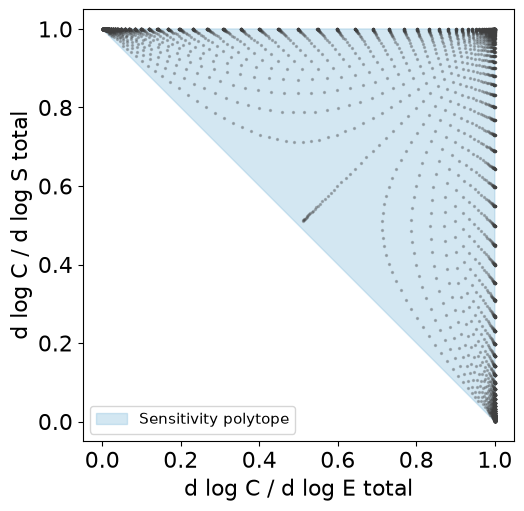

In [2]:
enzyme, substrate = np.meshgrid(
    np.geomspace(0.01, 1e4, 70), np.geomspace(0.01, 1e4, 70)
)
hE, hS = log_sensitivity(enzyme, substrate, K)
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.fill([1, 1, 0], [1, 0, 1], color="#91c3df", alpha=0.4, label="Sensitivity polytope")
ax.scatter(hE.ravel(), hS.ravel(), s=2, color="0.25", alpha=0.3)
ax.set(
    xlabel="d log C / d log E total",
    ylabel="d log C / d log S total",
    xlim=(-0.05, 1.05),
    ylim=(-0.05, 1.05),
    aspect="equal",
)
ax.legend(fontsize=11)
plt.show()

## Equilibrium output contracts

These contracts bound the output flux under explicit enzyme and substrate conditions.

In [3]:
for regime, contract in contracts.items():
    admitted = 0
    for E in np.geomspace(0.1, 1000, 35):
        for S in np.geomspace(0.1, 1000, 35):
            values = {
                Var("z_u"): np.log(E),
                Var("z_x"): np.log(S),
                Var("z_y"): np.log(kcat * binding_complex(E, S, K)),
            }
            if contract.a.contains_behavior(values):
                admitted += 1
                assert contract.g.contains_behavior(values)
    assert admitted > 0
    print(regime, admitted, "equilibrium points satisfy the contract")

K 289 equilibrium points satisfy the contract
substrate 318 equilibrium points satisfy the contract


enzyme 318 equilibrium points satisfy the contract


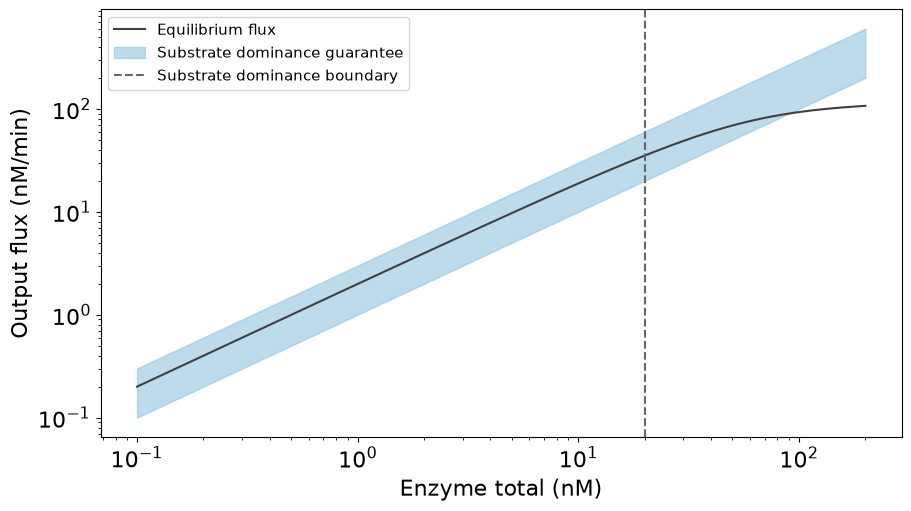

In [4]:
E = np.geomspace(0.1, 200, 250)
S = 40.0
flux = kcat * binding_complex(E, S, K)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.plot(E, flux, color="0.25", label="Equilibrium flux")
ax.fill_between(
    E, E, kcat * E, color="#91c3df", alpha=0.6, label="Substrate dominance guarantee"
)
ax.axvline(20, color="0.4", ls="--", label="Substrate dominance boundary")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Enzyme total (nM)",
    ylabel="Output flux (nM/min)",
)
ax.legend(fontsize=11)
plt.show()

## Michaelis Menten response

Under the substrate excess assumption $S\approx x$, the Michaelis Menten response is
$$y_{\mathrm{MM}}=\frac{k_{\mathrm{cat}}ux}{K+x}.$$
The Hill contracts apply with $n=1$, $s=x$, $d=u$, and $k=k_{\mathrm{cat}}$.

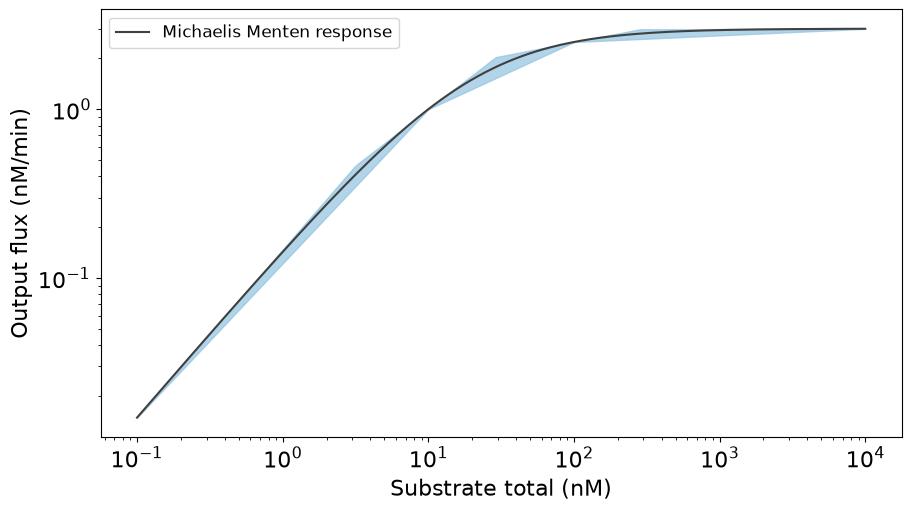

In [5]:
entries = hill_contracts(
    1,
    True,
    (K, K),
    (kcat, kcat),
    edges=(0.1, 10, 100, 1e4),
    dna_bounds=(0.01, 1e4),
    input_name="z_x",
    dna_name="z_u",
    output_name="z_y",
)
E = 1.0
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for entry in entries:
    S = np.geomspace(*entry["input_interval"], 100)
    lower, upper = hill_limits(entry, S, E)
    ax.fill_between(S, lower, upper, color="#91c3df", alpha=0.7)
S = np.geomspace(0.1, 1e4, 300)
ax.plot(S, kcat * E * S / (K + S), color="0.25", label="Michaelis Menten response")
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Substrate total (nM)",
    ylabel="Output flux (nM/min)",
)
ax.legend(fontsize=12)
plt.show()